<a href="https://colab.research.google.com/github/designerguy13-photonics/openEBL-2025-10/blob/main/EBeam_anurag_RR%26MZI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


=== RR1 analysis summary ===
Port: THROUGH
  Estimated FSR      : 0.062 nm
  Q (first resonance): 63
  ER (first dip)     : 25.14 dB
  First 3 resonances : 1475.008, 1475.040, 1475.072 nm

Port: DROP
  Estimated FSR      : 0.030 nm
  Q (first resonance): 40891
  ER (first dip)     : 10.46 dB
  First 3 resonances : 1475.008, 1475.024, 1475.040 nm

  through_IL_dB: 22.83 dB
  drop_IL_dB: 53.45 dB

=== RR2 analysis summary ===
Port: THROUGH
  Estimated FSR      : 0.062 nm
  Q (first resonance): 63
  ER (first dip)     : 25.14 dB
  First 3 resonances : 1475.008, 1475.040, 1475.072 nm

Port: DROP
  Estimated FSR      : 0.030 nm
  Q (first resonance): 40891
  ER (first dip)     : 10.46 dB
  First 3 resonances : 1475.008, 1475.024, 1475.040 nm

  through_IL_dB: 22.83 dB
  drop_IL_dB: 53.45 dB

=== RR3 analysis summary ===
Port: THROUGH
  Estimated FSR      : 0.060 nm
  Q (first resonance): 59
  ER (first dip)     : 24.05 dB
  First 3 resonances : 1475.008, 1475.024, 1475.040 nm

Port: DROP
 

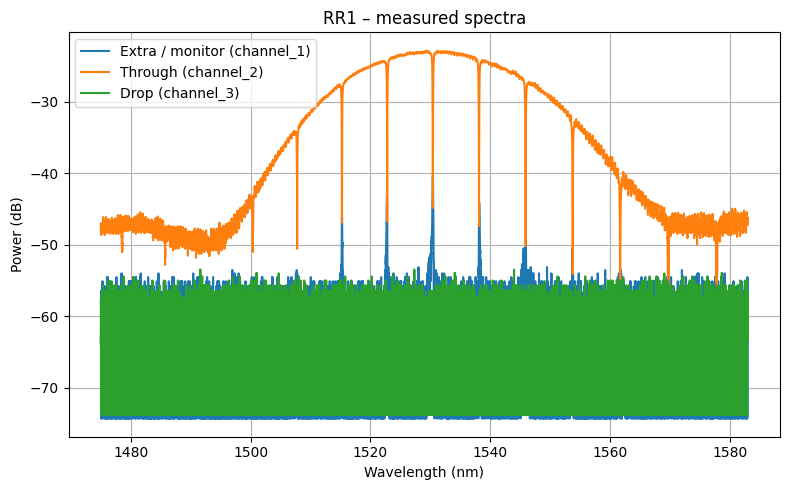

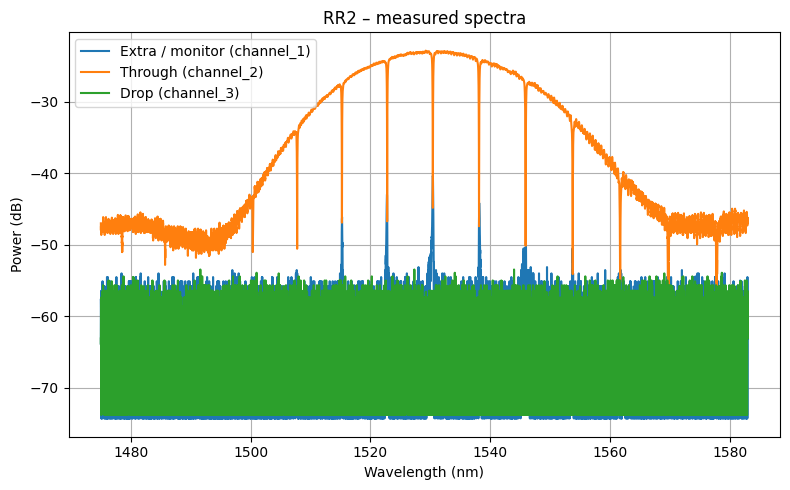

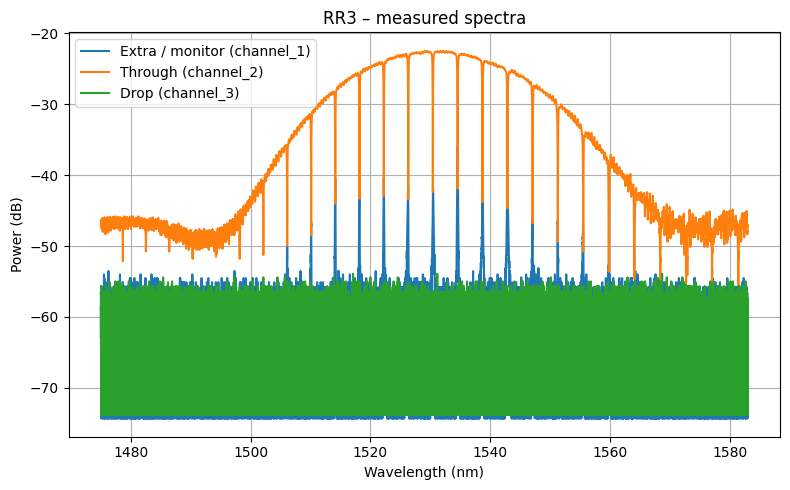

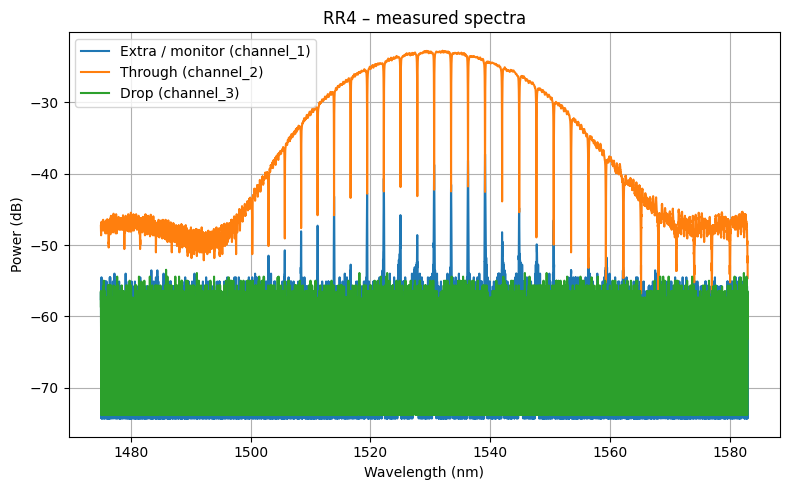

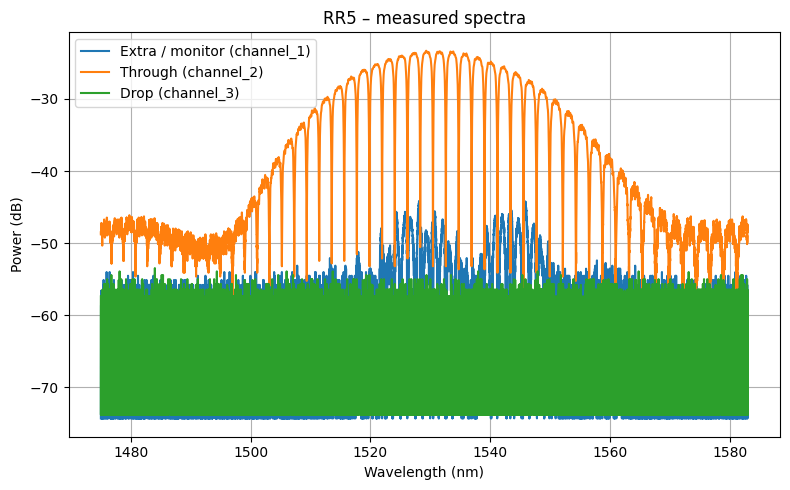

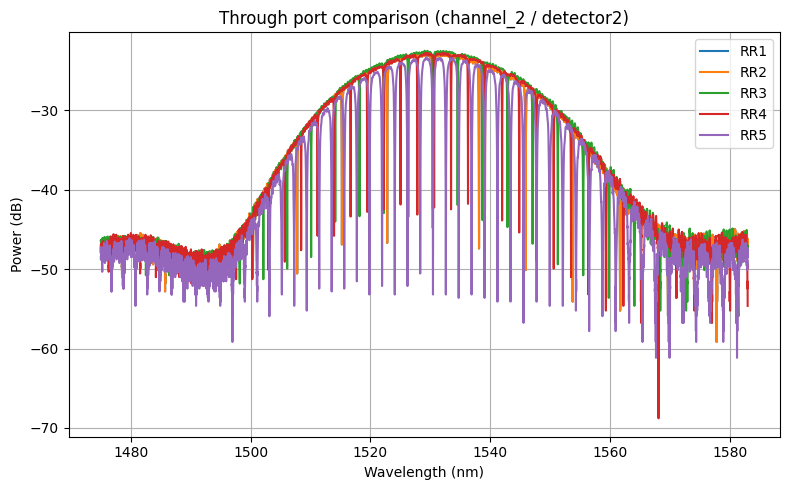

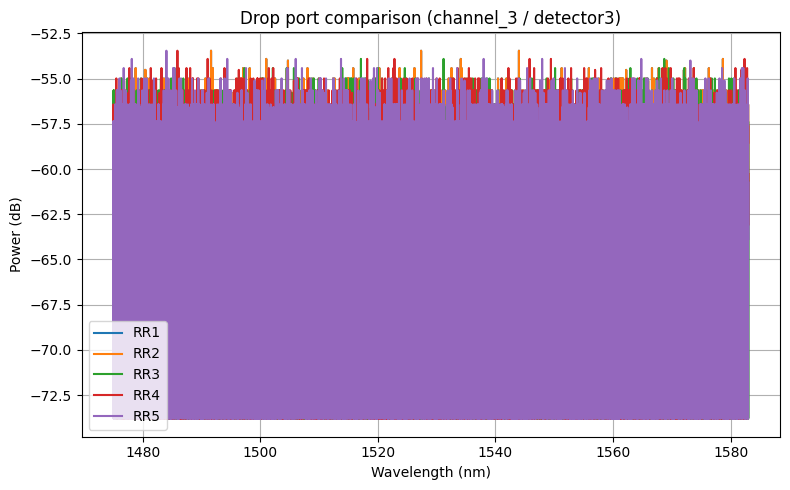

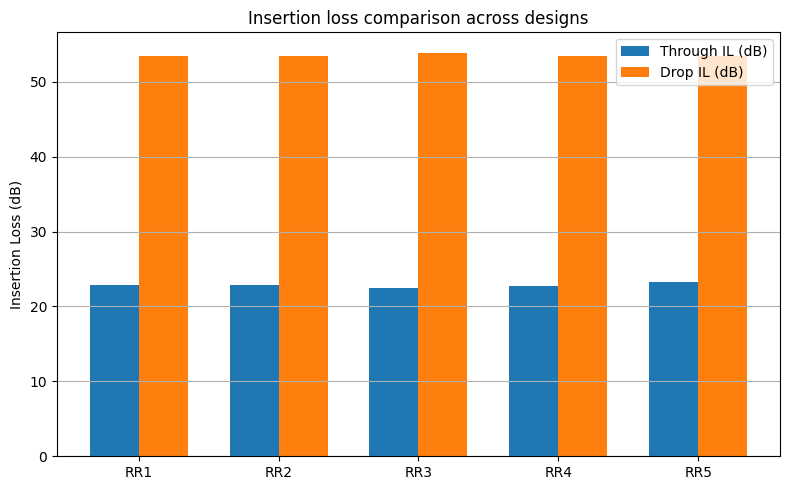


=== Summary table (copy into thesis) ===
Device | Port | FSR (nm) | Q_first | ER_first (dB) | IL (dB)
-------------------------------------------------------------
RR1   | through | 0.062   | 63   | 25.14       | 22.83
RR1   | drop   | 0.030   | 40891   | 10.46       | 53.45
RR2   | through | 0.062   | 63   | 25.14       | 22.83
RR2   | drop   | 0.030   | 40891   | 10.46       | 53.45
RR3   | through | 0.060   | 59   | 24.05       | 22.48
RR3   | drop   | 0.030   | 107750   | 9.20       | 53.91
RR4   | through | 0.059   | 691   | 25.88       | 22.74
RR4   | drop   | 0.030   | 315200   | 20.33       | 53.45
RR5   | through | 0.061   | 63   | 25.46       | 23.31
RR5   | drop   | 0.030   | 455232   | 20.33       | 53.45


In [7]:
"""
Multi-device ring resonator analysis (RR1–RR5)

- Expects files:
    /content/RR1_measured.csv
    /content/RR2_measured.csv
    /content/RR3_measured.csv
    /content/RR4_measured.csv
    /content/RR5_measured.csv

- CSV format (edX-style):
    wavelength, λ1, λ2, ...
    channel_1, P1(λ1), ...
    channel_2, P2(λ1), ...
    channel_3, P3(λ1), ...

- Optional .mat scandata:
    /content/17-Nov-2025 09.14.57.mat

Detector / channel mapping for *your* setup:
    detector1 -> channel_1 -> EXTRA / monitor
    detector2 -> channel_2 -> THROUGH port
    detector3 -> channel_3 -> DROP port
"""

import os
import numpy as np
import matplotlib.pyplot as plt


# ----------------------------------------------------------------------
# 1. LOADING FUNCTIONS
# ----------------------------------------------------------------------

def load_edx_csv(path):
    """
    Load measurement CSV of the form:

        wavelength, λ1, λ2, ...
        channel_1, P1(λ1), P1(λ2), ...
        channel_2, P2(λ1), P2(λ2), ...
        channel_3, P3(λ1), P3(λ2), ...

    Returns:
        lambda_nm : (N,) array of wavelength in nm
        channels  : dict {'channel_1': (N,), 'channel_2': ...} in dB
    """
    if not os.path.exists(path):
        raise FileNotFoundError(f"CSV file not found: {path}")

    with open(path, "r") as f:
        lines = [ln.strip() for ln in f.readlines()]

    # Remove commented lines starting with '#'
    data_lines = [ln for ln in lines if not ln.startswith("#")]
    if len(data_lines) < 4:
        raise ValueError(f"{path} does not contain expected wavelength + 3 channels.")

    # wavelength row
    wl_parts = data_lines[0].split(",")
    if not wl_parts[0].lower().startswith("wavelength"):
        raise ValueError(f"First data line in {path} must start with 'wavelength'.")
    lambda_nm = np.array([float(x) for x in wl_parts[1:]])

    channels = {}
    for row in data_lines[1:4]:
        parts = row.split(",")
        label = parts[0].strip()      # "channel_1" etc.
        values = np.array([float(x) for x in parts[1:]])
        channels[label] = values

    return lambda_nm, channels


def load_scandata_mat(path):
    """
    Load Python-style .mat file with scandata struct (optional).

    Expected structure:
        scandata.wavelength   % [N]
        scandata.power        % [N, Nchannels]

    Returns:
        lambda_nm : (N,) wavelength in nm
        channels  : dict {'channel_1': (N,), ...} in dB
    """
    import scipy.io as sio  # local import

    if not os.path.exists(path):
        raise FileNotFoundError(f"MAT file not found: {path}")

    mat = sio.loadmat(path, squeeze_me=True)
    scandata = mat["scandata"]

    lambda_m = np.array(scandata["wavelength"]).ravel()
    power = np.array(scandata["power"])

    def to_dB(arr):
        arr = np.array(arr, dtype=float)
        # If already in negative dB, keep; otherwise convert linear -> dB
        if arr.max() <= 0:
            return arr
        return 10 * np.log10(arr)

    channels = {}
    if power.ndim == 1:
        channels["channel_1"] = to_dB(power.ravel())
    else:
        n_ch = power.shape[1]
        for i in range(n_ch):
            channels[f"channel_{i+1}"] = to_dB(power[:, i])

    lambda_nm = lambda_m * 1e9
    return lambda_nm, channels


# ----------------------------------------------------------------------
# 2. ANALYSIS UTILITIES
# ----------------------------------------------------------------------

def normalize_trace(power_dB):
    """Normalize a transmission trace in dB so that the maximum = 0 dB."""
    return power_dB - np.max(power_dB)


def find_resonances(lambda_nm, power_dB_norm, min_depth_dB=-3):
    """
    Simple local-minima finder on a normalized (max=0 dB) trace.

    Args:
        lambda_nm      : wavelength array
        power_dB_norm  : normalized power (0 dB max, negative elsewhere)
        min_depth_dB   : only count minima deeper than this (e.g. -3 dB)

    Returns:
        res_lambda_nm : array of resonance wavelengths
        idxs          : indices of those resonances
    """
    l = lambda_nm
    p = power_dB_norm
    idxs = []

    for i in range(1, len(p) - 1):
        if p[i] < p[i - 1] and p[i] < p[i + 1] and p[i] < min_depth_dB:
            idxs.append(i)

    return l[idxs], np.array(idxs, dtype=int)


def estimate_fwhm(lambda_nm, power_dB_norm, idx):
    """
    Estimate FWHM around a particular resonance index.

    - power_dB_norm has max = 0 dB.
    - Resonance dip is at power_dB_norm[idx] (negative).
    - FWHM is the width between the two wavelengths where
      power crosses (dip + 3 dB) on each side.

    Returns:
        fwhm_nm   : approximate FWHM in nm
    """
    p = power_dB_norm
    l = lambda_nm
    dip = p[idx]
    half = dip + 3.0  # 3 dB above the minimum

    # search left
    left = idx
    while left > 0 and p[left] < half:
        left -= 1
    if left == idx:
        return np.nan
    l1, p1 = l[left], p[left]
    l2, p2 = l[left + 1], p[left + 1]
    wl_left = l1 + (half - p1) * (l2 - l1) / (p2 - p1)

    # search right
    right = idx
    while right < len(p) - 1 and p[right] < half:
        right += 1
    if right == idx:
        return np.nan
    r1, rp1 = l[right - 1], p[right - 1]
    r2, rp2 = l[right], p[right]
    wl_right = r1 + (half - rp1) * (r2 - r1) / (rp2 - rp1)

    return wl_right - wl_left


def analyze_ring(lambda_nm, power_dB, label="through"):
    """
    Perform basic analysis of a ring resonator trace:

        - normalization
        - find resonances (local minima)
        - estimate FSR (mean spacing)
        - estimate Q-factor at first resonance
        - estimate extinction ratio at first resonance

    Returns:
        analysis : dict with keys 'resonances_nm', 'FSR_nm',
                   'Q_first', 'ER_first_dB'
    """
    norm = normalize_trace(power_dB)
    res_lam, idxs = find_resonances(lambda_nm, norm, min_depth_dB=-3)

    if len(idxs) < 1:
        print(f"[WARN] No clear resonances found in {label} channel.")
        return {
            "resonances_nm": np.array([]),
            "FSR_nm": np.nan,
            "Q_first": np.nan,
            "ER_first_dB": np.nan,
        }

    # FSR from successive resonances
    if len(res_lam) >= 2:
        fsr = np.mean(np.diff(res_lam))
    else:
        fsr = np.nan

    # first resonance
    i0 = idxs[0]
    lambda0 = lambda_nm[i0]
    dip0 = norm[i0]          # negative value
    fwhm0 = estimate_fwhm(lambda_nm, norm, i0)
    Q0 = lambda0 / fwhm0 if np.isfinite(fwhm0) and fwhm0 > 0 else np.nan
    ER0 = -dip0              # extinction ratio in dB (0 - dip)

    return {
        "resonances_nm": res_lam,
        "FSR_nm": fsr,
        "Q_first": Q0,
        "ER_first_dB": ER0,
    }


def compute_insertion_loss(power_dB):
    """
    Simple insertion loss estimate:
    IL (dB) = - max(power_dB)

    If max power is -4 dB, IL = 4 dB.
    """
    return -np.nanmax(power_dB)


# ----------------------------------------------------------------------
# 3. PLOTTING + REPORT-READY SUMMARY
# ----------------------------------------------------------------------

def plot_ring(lambda_nm, channels, device_name="RR1"):
    """
    Plot EXTRA, THROUGH, DROP channels and run analysis.

    With your mapping:
        channel_1 -> extra
        channel_2 -> through
        channel_3 -> drop
    """
    extra   = channels.get("channel_1", None)  # detector1
    through = channels.get("channel_2", None)  # detector2 (THROUGH)
    drop    = channels.get("channel_3", None)  # detector3 (DROP)

    plt.figure(figsize=(8, 5))
    if extra is not None:
        plt.plot(lambda_nm, extra, label="Extra / monitor (channel_1)")
    if through is not None:
        plt.plot(lambda_nm, through, label="Through (channel_2)")
    if drop is not None:
        plt.plot(lambda_nm, drop, label="Drop (channel_3)")

    plt.xlabel("Wavelength (nm)")
    plt.ylabel("Power (dB)")
    plt.title(f"{device_name} – measured spectra")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()

    # --- Analysis on through and drop ports only ---
    results = {}
    if through is not None:
        results["through"] = analyze_ring(lambda_nm, through, label="through")
    if drop is not None:
        results["drop"] = analyze_ring(lambda_nm, drop, label="drop")

    IL = {}
    if through is not None:
        IL["through_IL_dB"] = compute_insertion_loss(through)
    if drop is not None:
        IL["drop_IL_dB"] = compute_insertion_loss(drop)

    # Print summary (for report)
    print(f"\n=== {device_name} analysis summary ===")
    for port, res in results.items():
        print(f"Port: {port.upper()}")
        print(f"  Estimated FSR      : {res['FSR_nm']:.3f} nm")
        print(f"  Q (first resonance): {res['Q_first']:.0f}")
        print(f"  ER (first dip)     : {res['ER_first_dB']:.2f} dB")
        if len(res["resonances_nm"]) > 0:
            print("  First 3 resonances :",
                  ", ".join(f"{x:.3f}" for x in res["resonances_nm"][:3]), "nm")
        print()
    for k, v in IL.items():
        print(f"  {k}: {v:.2f} dB")

    return results, IL


# ----------------------------------------------------------------------
# 4. MAIN – PROCESS RR1–RR5
# ----------------------------------------------------------------------
if __name__ == "__main__":
    DATA_DIR = "/content"   # change if your files are elsewhere

    devices = [
        {"name": "RR1", "csv": os.path.join(DATA_DIR, "/content/RR2_measured.csv")},
        {"name": "RR2", "csv": os.path.join(DATA_DIR, "/content/RR2_measured.csv")},
        {"name": "RR3", "csv": os.path.join(DATA_DIR, "/content/RR3_measured.csv")},
        {"name": "RR4", "csv": os.path.join(DATA_DIR, "/content/RR4_measured.csv")},
        {"name": "RR5", "csv": os.path.join(DATA_DIR, "/content/RR5_measyred.csv")},
    ]

    all_results = {}
    all_IL = {}
    all_lambda = {}
    all_channels = {}

    # ---- 4.1 Individual plots + analysis per device ----
    for dev in devices:
        name = dev["name"]
        csv_path = dev["csv"]

        try:
            lambda_nm, channels = load_edx_csv(csv_path)
        except Exception as e:
            print(f"\n[SKIP] {name}: problem loading {csv_path}: {e}")
            continue

        results, IL = plot_ring(lambda_nm, channels, device_name=name)
        all_results[name] = results
        all_IL[name] = IL
        all_lambda[name] = lambda_nm
        all_channels[name] = channels

    # ---- 4.2 Comparison plot: THROUGH port (channel_2) for all designs ----
    plt.figure(figsize=(8, 5))
    for name in all_lambda.keys():
        lambda_nm = all_lambda[name]
        ch = all_channels[name].get("channel_2", None)  # THROUGH
        if ch is None:
            continue
        plt.plot(lambda_nm, ch, label=name)
    plt.xlabel("Wavelength (nm)")
    plt.ylabel("Power (dB)")
    plt.title("Through port comparison (channel_2 / detector2)")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()

    # ---- 4.3 Comparison plot: DROP port (channel_3) for all designs ----
    plt.figure(figsize=(8, 5))
    for name in all_lambda.keys():
        lambda_nm = all_lambda[name]
        ch = all_channels[name].get("channel_3", None)  # DROP
        if ch is None:
            continue
        plt.plot(lambda_nm, ch, label=name)
    plt.xlabel("Wavelength (nm)")
    plt.ylabel("Power (dB)")
    plt.title("Drop port comparison (channel_3 / detector3)")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()

    # ---- 4.4 Insertion loss comparison bar plot ----
    dev_names = list(all_IL.keys())
    IL_through = [all_IL[d].get("through_IL_dB", np.nan) for d in dev_names]
    IL_drop = [all_IL[d].get("drop_IL_dB", np.nan) for d in dev_names]

    x = np.arange(len(dev_names))
    width = 0.35

    plt.figure(figsize=(8, 5))
    plt.bar(x - width/2, IL_through, width, label="Through IL (dB)")
    plt.bar(x + width/2, IL_drop, width, label="Drop IL (dB)")
    plt.xticks(x, dev_names)
    plt.ylabel("Insertion Loss (dB)")
    plt.title("Insertion loss comparison across designs")
    plt.grid(axis="y")
    plt.legend()
    plt.tight_layout()

    # ---- 4.5 Optional: Analyse RR1 MAT as well ----
    # Uncomment if you have the MAT file in /content:
    # try:
    #     mat_file = os.path.join(DATA_DIR, "17-Nov-2025 09.14.57.mat")
    #     lambda_nm_mat, channels_mat = load_scandata_mat(mat_file)
    #     plot_ring(lambda_nm_mat, channels_mat, device_name="RR1 (MAT)")
    # except Exception as e:
    #     print(f"[INFO] Could not process MAT file: {e}")

    plt.show()

    # ---- 4.6 Print compact summary table for thesis/report ----
    print("\n=== Summary table (copy into thesis) ===")
    print("Device | Port | FSR (nm) | Q_first | ER_first (dB) | IL (dB)")
    print("-------------------------------------------------------------")
    for name, res in all_results.items():
        for port in ["through", "drop"]:
            if port in res:
                r = res[port]
                il_key = f"{port}_IL_dB"
                il_val = all_IL[name].get(il_key, np.nan)
                print(f"{name:5s} | {port:6s} | "
                      f"{r['FSR_nm']:.3f}   | "
                      f"{r['Q_first']:.0f}   | "
                      f"{r['ER_first_dB']:.2f}       | "
                      f"{il_val:.2f}")


In [7]:
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy.signal import find_peaks

# ---------------------------------------------------------
# Load CSV (edX format)
# ---------------------------------------------------------

def load_edx_csv(path):
    with open(path, "r") as f:
        lines = [ln.strip() for ln in f]

    data_lines = [ln for ln in lines if not ln.startswith("#")]
    wl_parts = data_lines[0].split(",")
    lambda_nm = np.array([float(x) for x in wl_parts[1:]])

    channels = {}
    for row in data_lines[1:4]:
        parts = row.split(",")
        label = parts[0]
        vals = np.array([float(v) for v in parts[1:]])
        channels[label] = vals

    return lambda_nm, channels


# ---------------------------------------------------------
# Improved FSR detection (detect high-frequency peaks)
# ---------------------------------------------------------

def find_fsr(lambda_nm, trace_dB, prominence_dB=1, min_fsr_nm=0.02, max_fsr_nm=15):
    # Remove slow envelope
    window = 400
    envelope = np.convolve(trace_dB, np.ones(window)/window, mode='same')
    hf = trace_dB - envelope

    peaks, _ = find_peaks(hf, prominence=prominence_dB)

    if len(peaks) < 3:
        return np.nan, peaks

    fs = np.diff(lambda_nm[peaks])

    valid = [x for x in fs if min_fsr_nm < x < max_fsr_nm]
    if len(valid) == 0:
        return np.nan, peaks

    return np.mean(valid), peaks


# ---------------------------------------------------------
# Compute ER, IL, Visibility
# ---------------------------------------------------------

def compute_metrics(trace):
    Pmax = np.max(trace)
    Pmin = np.min(trace)
    ER = Pmax - Pmin
    IL = -(np.mean(trace))     # relative IL
    V = (Pmax - Pmin) / (Pmax + Pmin + 1e-9)
    return ER, IL, V


# ---------------------------------------------------------
# ΔL values (from design)
# ---------------------------------------------------------

DESIGN_DELTA_L = {
    "MZI1": 152,
    "MZI2": 92,
    "MZI3": 232,
    "MZI4": 7681,
}

def fsr_from_deltaL(deltaL_um, lambda_nm=1550, n_g=4.25):
    lam = lambda_nm * 1e-9
    dL = deltaL_um * 1e-6
    return (lam**2 / (4.25 * dL)) * 1e9


# ---------------------------------------------------------
# Main Analysis Function
# ---------------------------------------------------------

def analyze_MZI(name, path):
    lambda_nm, ch = load_edx_csv(path)
    det1 = ch["channel_1"]
    det2 = ch["channel_2"]

    # --- FSR ---
    fsr_meas, peaks = find_fsr(lambda_nm, det2)
    fsr_exp = fsr_from_deltaL(DESIGN_DELTA_L[name])

    # --- Metrics ---
    ER1, IL1, V1 = compute_metrics(det1)
    ER2, IL2, V2 = compute_metrics(det2)
    IL_diff = abs(IL1 - IL2)

    print(f"\n===== {name} =====")
    print(f"ΔL design       : {DESIGN_DELTA_L[name]} µm")
    print(f"FSR expected    : {fsr_exp:.4f} nm")
    print(f"FSR measured    : {fsr_meas:.4f} nm")
    print(f"ER port1        : {ER1:.2f} dB")
    print(f"ER port2        : {ER2:.2f} dB")
    print(f"Mean IL port1   : {IL1:.2f} dB")
    print(f"Mean IL port2   : {IL2:.2f} dB")
    print(f"IL mismatch     : {IL_diff:.2f} dB")
    print(f"Visibility1     : {V1:.3f}")
    print(f"Visibility2     : {V2:.3f}")

    # Return summary
    return {
        "name": name,
        "deltaL": DESIGN_DELTA_L[name],
        "fsr_exp": fsr_exp,
        "fsr_meas": fsr_meas,
        "ER1": ER1,
        "ER2": ER2,
        "IL1": IL1,
        "IL2": IL2,
        "ILdiff": IL_diff,
        "V1": V1,
        "V2": V2,
    }

# ---------------------------------------------------------
# Run for all MZIs
# ---------------------------------------------------------

FILES = {
    "MZI1": "/content/MZI 1.23.19.csv",
    "MZI2": "/content/MZI 2.21.56.csv",
    "MZI3": "/content/MZI 3.20.32.csv",
    "MZI4": "/content/MZI 4.18.49.csv",
}

results = []
for name, file in FILES.items():
    results.append(analyze_MZI(name, file))


# ---------------------------------------------------------
# Summary table for report
# ---------------------------------------------------------

print("\n\n==== SUMMARY TABLE FOR REPORT ====\n")
print("Device | ΔL (um) | FSR_exp | FSR_meas | ER1 | ER2 | IL1 | IL2 | Vis1 | Vis2")
print("-------------------------------------------------------------------------------")
for r in results:
    print(f"{r['name']:5s} | {r['deltaL']:7.1f} | {r['fsr_exp']:.3f} | {r['fsr_meas']:.3f} | "
          f"{r['ER1']:.1f} | {r['ER2']:.1f} | {r['IL1']:.1f} | {r['IL2']:.1f} | "
          f"{r['V1']:.2f} | {r['V2']:.2f}")



===== MZI1 =====
ΔL design       : 152 µm
FSR expected    : 3.7190 nm
FSR measured    : 0.1957 nm
ER port1        : 41.76 dB
ER port2        : 46.45 dB
Mean IL port1   : 40.37 dB
Mean IL port2   : 40.62 dB
IL mismatch     : 0.25 dB
Visibility1     : -0.486
Visibility2     : -0.510

===== MZI2 =====
ΔL design       : 92 µm
FSR expected    : 6.1445 nm
FSR measured    : 0.2004 nm
ER port1        : 38.50 dB
ER port2        : 42.65 dB
Mean IL port1   : 40.12 dB
Mean IL port2   : 39.96 dB
IL mismatch     : 0.15 dB
Visibility1     : -0.465
Visibility2     : -0.488

===== MZI3 =====
ΔL design       : 232 µm
FSR expected    : 2.4366 nm
FSR measured    : 0.2517 nm
ER port1        : 42.48 dB
ER port2        : 43.18 dB
Mean IL port1   : 39.43 dB
Mean IL port2   : 39.81 dB
IL mismatch     : 0.37 dB
Visibility1     : -0.498
Visibility2     : -0.497

===== MZI4 =====
ΔL design       : 7681 µm
FSR expected    : 0.0736 nm
FSR measured    : 0.0726 nm
ER port1        : 41.26 dB
ER port2        : 38.44 d


===== MZI1 =====
ΔL design      : 152 µm
FSR expected   : 3.7190 nm
FSR measured   : 4.7943 nm
ER Det1        : 41.76 dB
ER Det2        : 46.45 dB
IL Det1        : 40.37 dB
IL Det2        : 40.62 dB
IL mismatch    : 0.25 dB
Visibility Det1: -0.486
Visibility Det2: -0.510

===== MZI2 =====
ΔL design      : 92 µm
FSR expected   : 6.1445 nm
FSR measured   : 9.0785 nm
ER Det1        : 38.50 dB
ER Det2        : 42.65 dB
IL Det1        : 40.12 dB
IL Det2        : 39.96 dB
IL mismatch    : 0.15 dB
Visibility Det1: -0.465
Visibility Det2: -0.488

===== MZI3 =====
ΔL design      : 232 µm
FSR expected   : 2.4366 nm
FSR measured   : 2.8422 nm
ER Det1        : 42.48 dB
ER Det2        : 43.18 dB
IL Det1        : 39.43 dB
IL Det2        : 39.81 dB
IL mismatch    : 0.37 dB
Visibility Det1: -0.498
Visibility Det2: -0.497

===== MZI4 =====
ΔL design      : 7681 µm
FSR expected   : 0.0736 nm
FSR measured   : 0.0726 nm
ER Det1        : 41.26 dB
ER Det2        : 38.44 dB
IL Det1        : 40.44 dB
IL Det2

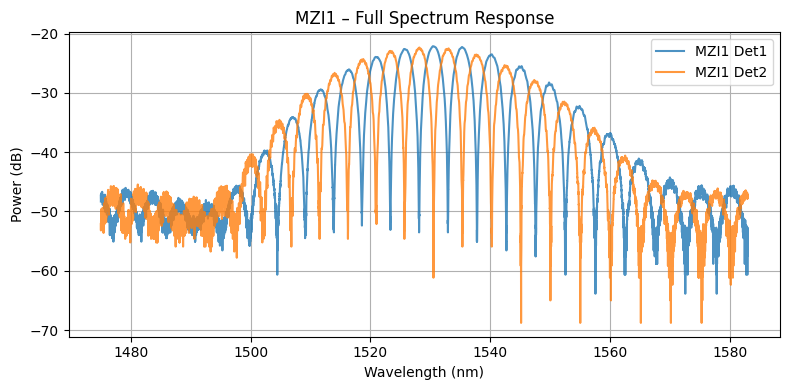

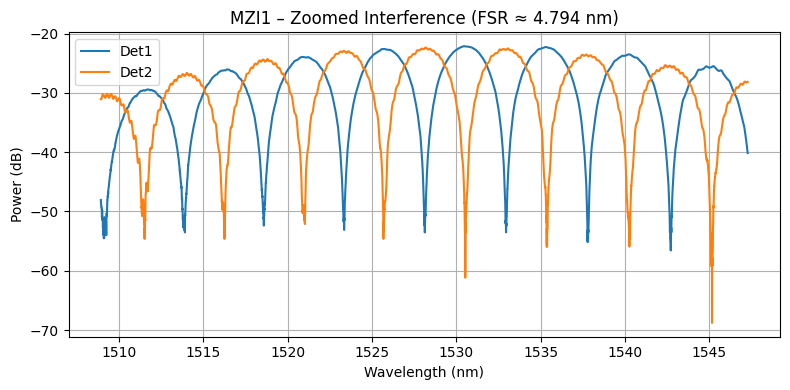

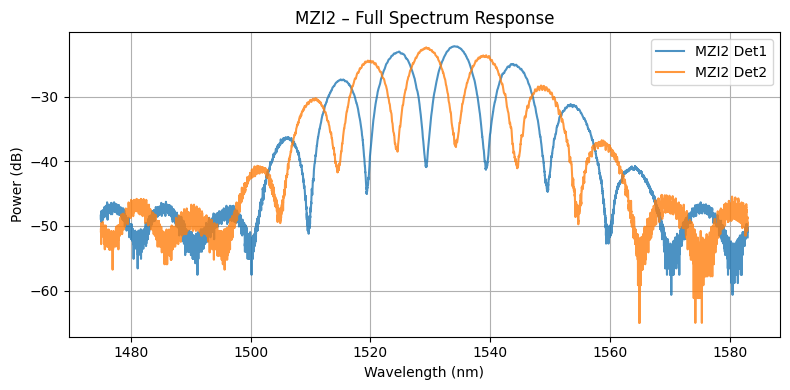

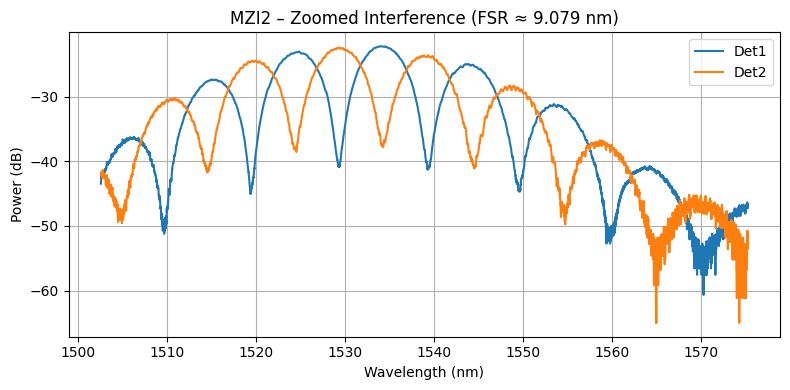

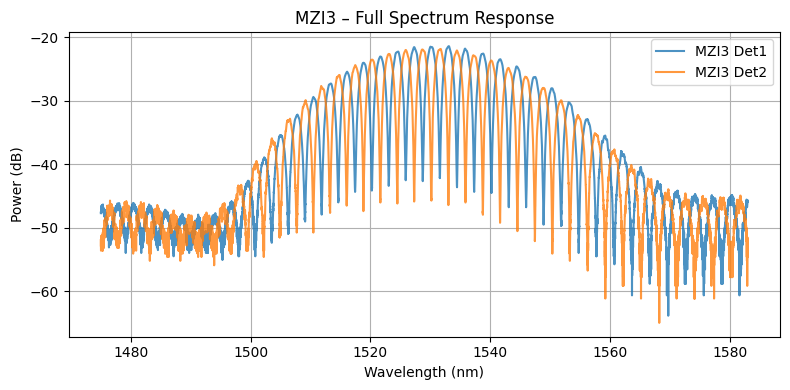

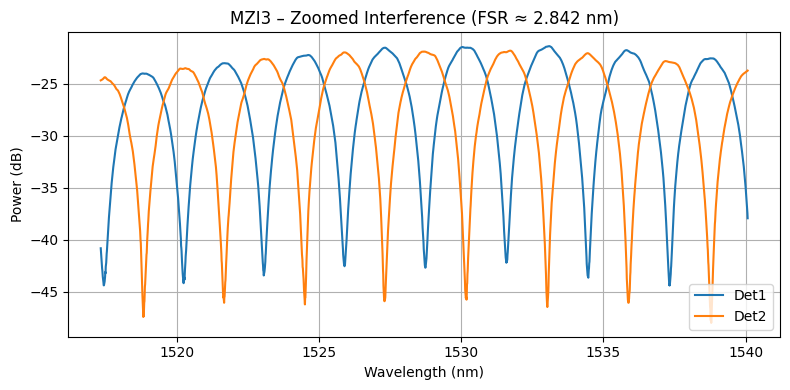

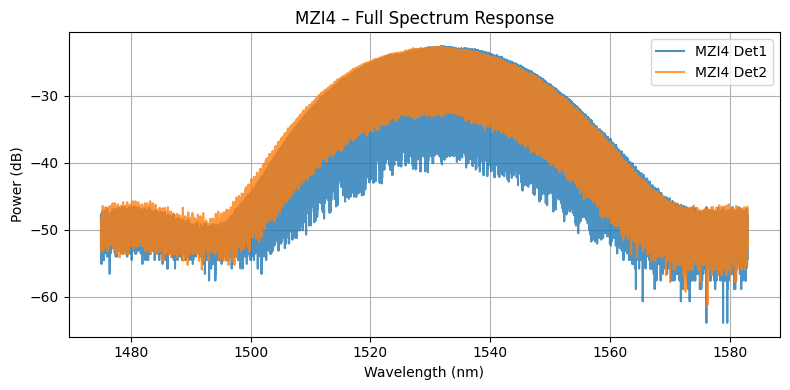

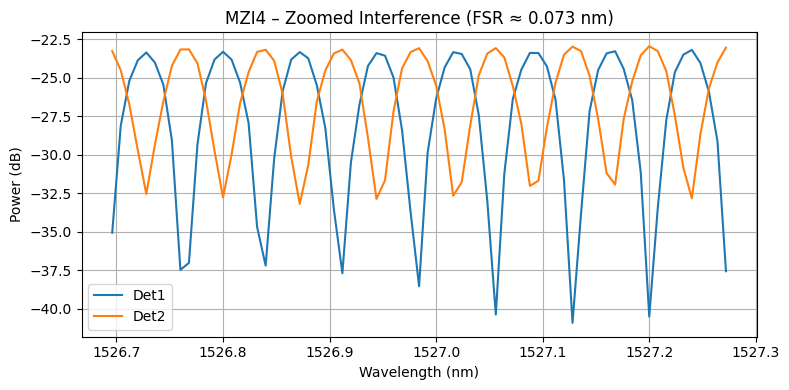

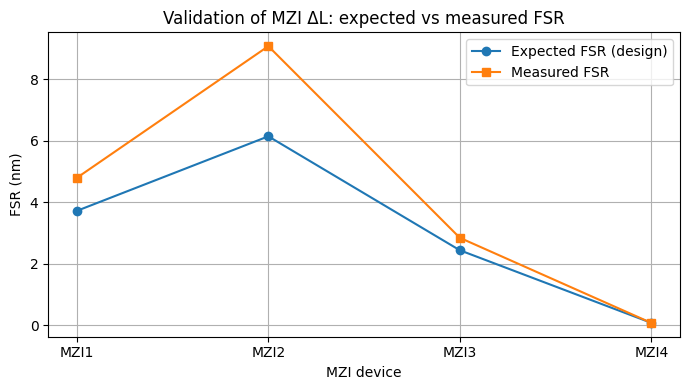


==== SUMMARY TABLE FOR REPORT ====

Device | ΔL(µm) | FSR_exp | FSR_meas | ER1 | ER2 | IL1 | IL2 | V1 | V2
-----------------------------------------------------------------------
MZI1  |   152.0 | 3.719 | 4.794 | 41.8 | 46.5 | 40.4 | 40.6 | -0.49 | -0.51
MZI2  |    92.0 | 6.145 | 9.079 | 38.5 | 42.7 | 40.1 | 40.0 | -0.46 | -0.49
MZI3  |   232.0 | 2.437 | 2.842 | 42.5 | 43.2 | 39.4 | 39.8 | -0.50 | -0.50
MZI4  |  7681.0 | 0.074 | 0.073 | 41.3 | 38.4 | 40.4 | 39.6 | -0.48 | -0.46


In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# =========================================================
# 1. Load CSV (edX format)
# =========================================================

def load_edx_csv(path):
    with open(path, "r") as f:
        lines = [ln.strip() for ln in f]

    data_lines = [ln for ln in lines if not ln.startswith("#")]
    wl_parts = data_lines[0].split(",")
    lambda_nm = np.array([float(x) for x in wl_parts[1:]])

    channels = {}
    for row in data_lines[1:4]:
        parts = row.split(",")
        label = parts[0]
        vals = np.array([float(v) for v in parts[1:]])
        channels[label] = vals

    return lambda_nm, channels


# =========================================================
# 2. Helpers: smoothing, metrics
# =========================================================

def smooth(trace, window_pts=201):
    window_pts = max(3, int(window_pts))
    kernel = np.ones(window_pts) / window_pts
    return np.convolve(trace, kernel, mode="same")

def compute_metrics(trace_dB):
    """Extinction ratio, insertion loss, visibility."""
    Pmax = np.max(trace_dB)
    Pmin = np.min(trace_dB)
    ER = Pmax - Pmin                   # dB
    IL = -np.mean(trace_dB)            # dB, relative IL
    V = (Pmax - Pmin) / (Pmax + Pmin + 1e-9)
    return ER, IL, V


# =========================================================
# 3. Design ΔL and theoretical FSR
# =========================================================

DESIGN_DELTA_L = {
    "MZI1": 152,      # microns
    "MZI2": 92,
    "MZI3": 232,
    "MZI4": 7681,
}

def fsr_from_deltaL(deltaL_um, lambda_nm=1550, n_g=4.25):
    lam = lambda_nm * 1e-9
    dL = deltaL_um * 1e-6
    fsr_m = lam**2 / (n_g * dL)
    return fsr_m * 1e9   # nm


# =========================================================
# 4. Smart FSR detection
# =========================================================

def smart_find_fsr(lambda_nm, trace_dB, fsr_expected,
                   prominence_dB=1.0, ng=4.25):
    """
    Hybrid FSR detector:
      - if fsr_expected > 1 nm -> slow fringes: use SMOOTHED trace
      - if fsr_expected <= 1 nm -> fast fringes: use HIGH-PASS trace
    """

    if np.isnan(fsr_expected) or fsr_expected <= 0:
        # fall back to generic high-pass detection
        fsr_expected = 0.5

    if fsr_expected > 1.0:
        # --- slow fringes (small ΔL): LOW-PASS / SMOOTHED signal ---
        # choose smoothing window so that it averages over ~0.3 nm
        dlam = np.mean(np.diff(lambda_nm))
        pts_03nm = max(5, int(0.3 / dlam))  # points in 0.3 nm
        sig = smooth(trace_dB, pts_03nm)
    else:
        # --- fast fringes (large ΔL): HIGH-PASS signal ---
        window = 400   # wide window to capture envelope
        envelope = smooth(trace_dB, window)
        sig = trace_dB - envelope

    # find peaks on chosen signal
    peaks, _ = find_peaks(sig, prominence=prominence_dB)
    if len(peaks) < 3:
        return np.nan, peaks

    spacings = np.diff(lambda_nm[peaks])

    # keep spacings within a band around expected FSR
    lo = 0.3 * fsr_expected
    hi = 3.0 * fsr_expected
    valid = [s for s in spacings if lo < s < hi]

    if len(valid) == 0:
        return np.nan, peaks

    return float(np.mean(valid)), peaks


# =========================================================
# 5. Main analysis function (with plots)
# =========================================================

def analyze_MZI(name, path):
    lambda_nm, ch = load_edx_csv(path)

    # NOTE: adjust mapping if needed:
    # here we assume channel_1 = Det1, channel_2 = Det2
    det1 = ch["channel_1"]
    det2 = ch["channel_2"]

    # theoretical FSR from design ΔL
    fsr_exp = fsr_from_deltaL(DESIGN_DELTA_L[name])

    # measured FSR using smart detector (use det2)
    fsr_meas, peaks = smart_find_fsr(lambda_nm, det2, fsr_exp)

    # metrics for both detectors
    ER1, IL1, V1 = compute_metrics(det1)
    ER2, IL2, V2 = compute_metrics(det2)
    ILdiff = abs(IL1 - IL2)

    # --------- print numeric summary ---------
    print(f"\n===== {name} =====")
    print(f"ΔL design      : {DESIGN_DELTA_L[name]} µm")
    print(f"FSR expected   : {fsr_exp:.4f} nm")
    print(f"FSR measured   : {fsr_meas:.4f} nm")
    print(f"ER Det1        : {ER1:.2f} dB")
    print(f"ER Det2        : {ER2:.2f} dB")
    print(f"IL Det1        : {IL1:.2f} dB")
    print(f"IL Det2        : {IL2:.2f} dB")
    print(f"IL mismatch    : {ILdiff:.2f} dB")
    print(f"Visibility Det1: {V1:.3f}")
    print(f"Visibility Det2: {V2:.3f}")

    # --------- plots ---------

    # 1) full spectrum
    plt.figure(figsize=(8,4))
    plt.plot(lambda_nm, det1, label=f"{name} Det1", alpha=0.8)
    plt.plot(lambda_nm, det2, label=f"{name} Det2", alpha=0.8)
    plt.title(f"{name} – Full Spectrum Response")
    plt.xlabel("Wavelength (nm)")
    plt.ylabel("Power (dB)")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()

    # 2) zoom on a few fringes: center around a median peak if we have enough
    if len(peaks) > 3:
        mid = peaks[len(peaks)//2]
        # span roughly 3–4 fringes on each side
        if not np.isnan(fsr_meas) and fsr_meas > 0:
            span_nm = 4 * fsr_meas
        else:
            span_nm = 10.0  # fallback
        lam_mid = lambda_nm[mid]
        lam_min = lam_mid - span_nm
        lam_max = lam_mid + span_nm
        mask = (lambda_nm >= lam_min) & (lambda_nm <= lam_max)
    else:
        # fallback: central 10 nm window
        lam_center = 0.5 * (lambda_nm[0] + lambda_nm[-1])
        mask = (lambda_nm >= lam_center-5) & (lambda_nm <= lam_center+5)

    plt.figure(figsize=(8,4))
    plt.plot(lambda_nm[mask], det1[mask], label="Det1")
    plt.plot(lambda_nm[mask], det2[mask], label="Det2")
    title_fs = f"{name} – Zoomed Interference"
    if not np.isnan(fsr_meas):
        title_fs += f" (FSR ≈ {fsr_meas:.3f} nm)"
    plt.title(title_fs)
    plt.xlabel("Wavelength (nm)")
    plt.ylabel("Power (dB)")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()

    return {
        "name": name,
        "deltaL": DESIGN_DELTA_L[name],
        "fsr_exp": fsr_exp,
        "fsr_meas": fsr_meas,
        "ER1": ER1, "ER2": ER2,
        "IL1": IL1, "IL2": IL2,
        "ILdiff": ILdiff,
        "V1": V1, "V2": V2,
    }


# =========================================================
# 6. Run analysis for all MZIs
# =========================================================

FILES = {
    "MZI1": "/content/MZI 1.23.19.csv",
    "MZI2": "/content/MZI 2.21.56.csv",
    "MZI3": "/content/MZI 3.20.32.csv",
    "MZI4": "/content/MZI 4.18.49.csv",
}

results = []
for name, path in FILES.items():
    results.append(analyze_MZI(name, path))

plt.show()

# =========================================================
# 7. Validation plot: expected vs measured FSR
# =========================================================

names = [r["name"] for r in results]
fsr_exp_list = [r["fsr_exp"] for r in results]
fsr_meas_list = [r["fsr_meas"] for r in results]

plt.figure(figsize=(7,4))
plt.plot(names, fsr_exp_list, "o-", label="Expected FSR (design)")
plt.plot(names, fsr_meas_list, "s-", label="Measured FSR")
plt.xlabel("MZI device")
plt.ylabel("FSR (nm)")
plt.title("Validation of MZI ΔL: expected vs measured FSR")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# =========================================================
# 8. Summary table for report
# =========================================================

print("\n==== SUMMARY TABLE FOR REPORT ====\n")
print("Device | ΔL(µm) | FSR_exp | FSR_meas | ER1 | ER2 | IL1 | IL2 | V1 | V2")
print("-----------------------------------------------------------------------")
for r in results:
    print(f"{r['name']:5s} | {r['deltaL']:7.1f} | {r['fsr_exp']:.3f} | {r['fsr_meas']:.3f} | "
          f"{r['ER1']:.1f} | {r['ER2']:.1f} | {r['IL1']:.1f} | {r['IL2']:.1f} | "
          f"{r['V1']:.2f} | {r['V2']:.2f}")
